## Imports & Initialization:

In [94]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json
from knowledge_maze.evaluation.llm_judge_annotation.judge_annotation import JudgeDatasetManager, JudgeAuditTagger

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Get Annotation Subsets:

In [89]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
mistral_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))

deepseek_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
google_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
meta_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

deepseek_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/deepseek_deepseek-v4-flash.json"))
google_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/google_gemini-3-flash-preview.json"))
meta_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/meta-llama_llama-4-maverick.json"))

deepseek_v4_pro_res = load_json(os.path.join(REPO_PATH, "results/scaling/deepseek_deepseek-v4-pro.json"))
gpt_5_4_res = load_json(os.path.join(REPO_PATH, "results/scaling/openai_gpt-5.4.json"))

In [90]:
experiment_data_map = {
    "main": {
        "Deepseek V4 Flash": deepseek_baseline_res,
        "Gemini 3 Flash": google_baseline_res,
        "Llama 4 Maverick": meta_baseline_res,
        "GPT 5.4 Mini": gpt_baseline_res,
        "Mistral Medium 3.1": mistral_baseline_res,
    },
    "cot": {
        "Deepseek V4 Flash": deepseek_cot_res,
        "Gemini 3 Flash": google_cot_res,
        "Llama 4 Maverick": meta_cot_res,
    },
    "hedge": {
        "Deepseek V4 Flash": deepseek_hedged_res,
        "Gemini 3 Flash": google_hedged_res,
        "Llama 4 Maverick": meta_hedged_res,
    },
    "scaling": {
        "Deepseek V4 Pro": deepseek_v4_pro_res,
        "GPT 5.4": gpt_5_4_res,
    },
}

In [142]:
# Instantiate the complete pipeline module
manager = JudgeDatasetManager(experiment_data_map)

# Step 1: Create your unified golden-proportions target pool (e.g., N=400)
validation_pool = manager.create_validation_set(total_target=400)

# Step 2: Split among 4 annotators with a guaranteed overlap of 33 items for EVERY pair combination
annotator_packages = manager.split_for_annotators(x_annotators=4, y_shared=33)


=== Curation Completed: Gathered 400 Samples ===
Subclass Profile                 | True Population | Curated Subsample
----------------------------------------------------------------------
Ack: False | Class: abstain      | 5               | 3                
Ack: False | Class: claim        | 11188           | 150              
Ack: False | Class: evidence     | 2792            | 75               
Ack: False | Class: memory       | 20              | 6                
Ack: False | Class: other        | 100             | 14               
Ack: True  | Class: abstain      | 75              | 12               
Ack: True  | Class: claim        | 1946            | 63               
Ack: True  | Class: evidence     | 1716            | 59               
Ack: True  | Class: memory       | 23              | 7                
Ack: True  | Class: other        | 57              | 11               

=== Partition Completed for 4 Annotators (Pairwise Target Overlap: 33) ===
Annotator_1: Assigned 

# Tag Judge Evaluation Validity:

In [99]:
dataset_to_annotate = load_json(os.path.join(REPO_PATH, "knowledge_maze/evaluation/llm_judge_annotation/data_to_annotate/annotator_1.json"))
auditor = JudgeAuditTagger(dataset_to_annotate, save_file="judge_accuracy_checks.json")
auditor.display()

Output()

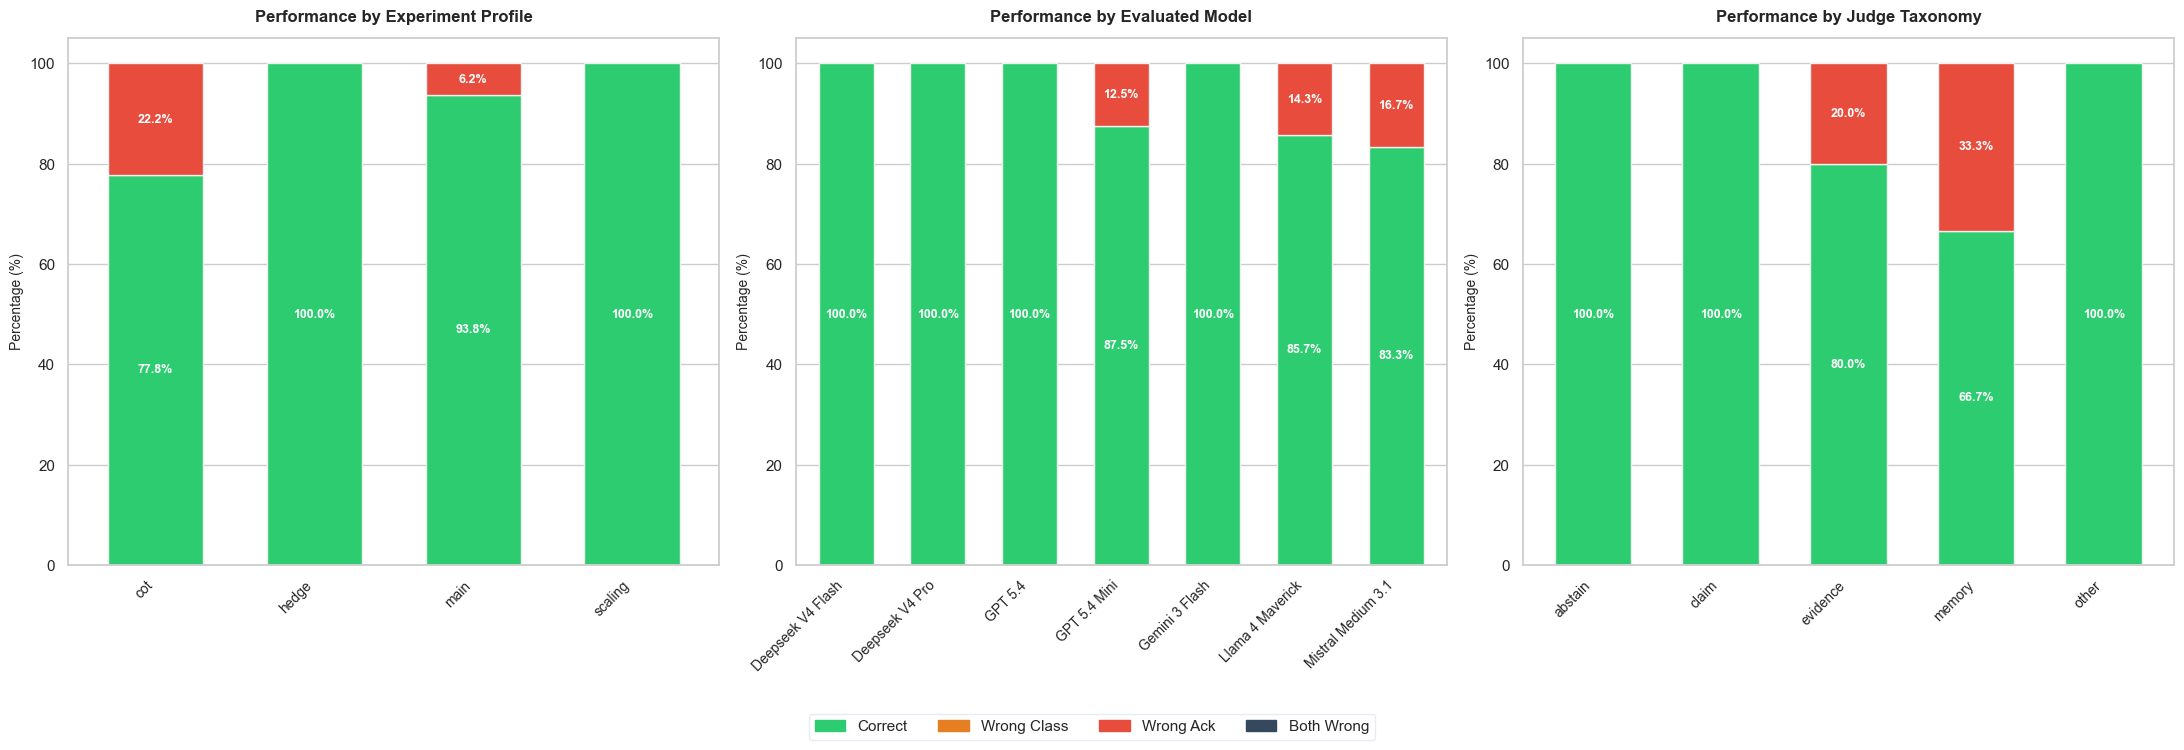

In [116]:
auditor.plot_results(manager.true_distribution)

In [143]:
def profile_annotation_subsets(batches):
    """
    Profiles overlapping and unique responses across multiple annotators.
    Guarantees that different model responses to the same question ID are 
    tracked as completely distinct evaluation samples.
    """
    # Create a unique response signature so sibling models aren't collapsed
    def get_response_signature(x): 
        if isinstance(x, dict):
            # Combine the question ID with the specific model response attributes
            return (x.get('sample_id'), x.get('model_name'), x.get('experiment_type'), x.get('raw_response'), x.get('explanation'))
        return x
    
    # Use the unique tuple signature instead of just the sample_id string
    annotator_sets = {name: {get_response_signature(item) for item in items} for name, items in batches.items()}
    all_annotators = list(annotator_sets.keys())
    
    # 1. Map every observed response signature to the exact group of annotators who received it
    sample_to_annotators = defaultdict(set)
    for name, s_set in annotator_sets.items():
        for response_sig in s_set:
            sample_to_annotators[response_sig].add(name)
            
    # 2. Invert mapping to find counts per combination profile
    combination_counts = defaultdict(int)
    for response_sig, annotators in sample_to_annotators.items():
        combination_counts[tuple(sorted(annotators))] += 1

    # --- Print Diagnostics ---
    print("=== Detailed Response-Level Annotation Combinations ===")
    
    unique_total = 0
    shared_total = 0
    
    for combo in sorted(combination_counts.keys(), key=lambda x: (len(x), x)):
        count = combination_counts[combo]
        combo_str = ", ".join(combo)
        
        if len(combo) == 1:
            print(f"🥇 Unique to [{combo_str}]: {count} unique responses")
            unique_total += count
        else:
            print(f"👥 Shared by [{combo_str}]: {count} unique responses")
            shared_total += count

    print("\n" + "="*40)
    print("=== Global Dataset Summary (Unique Responses) ===")
    print(f"Total Unique Responses (Seen by 1 person): {unique_total}")
    print(f"Total Shared Responses (Seen by >=2 people): {shared_total}")
    print(f"Total Distinct Response Pool Size: {len(sample_to_annotators)}")
    print("="*40)

 
profile_annotation_subsets(annotator_packages)

=== Detailed Response-Level Annotation Combinations ===
🥇 Unique to [Annotator_1]: 51 unique responses
🥇 Unique to [Annotator_2]: 51 unique responses
🥇 Unique to [Annotator_3]: 50 unique responses
🥇 Unique to [Annotator_4]: 49 unique responses
👥 Shared by [Annotator_1, Annotator_2]: 33 unique responses
👥 Shared by [Annotator_1, Annotator_3]: 33 unique responses
👥 Shared by [Annotator_1, Annotator_4]: 33 unique responses
👥 Shared by [Annotator_2, Annotator_3]: 33 unique responses
👥 Shared by [Annotator_2, Annotator_4]: 33 unique responses
👥 Shared by [Annotator_3, Annotator_4]: 33 unique responses

=== Global Dataset Summary (Unique Responses) ===
Total Unique Responses (Seen by 1 person): 201
Total Shared Responses (Seen by >=2 people): 198
Total Distinct Response Pool Size: 399
